In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import string
from collections import Counter
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC, NuSVC
from wordcloud import WordCloud

nltk.download('stopwords')
from nltk.corpus import stopwords

plt.style.use('ggplot')

# Tạo thư mục chứa dữ liệu
!mkdir -p /data/raw

# Tải folder từ Google Drive
FILE_ID = "13jNVh_ONsb556OC_MBfLYZbBVXLWXEqW"
!gdown --folder --id $FILE_ID -O /data/raw/

# Đọc file csv
df = pd.read_csv("/data/raw/raw/IMDB Dataset.csv")

# Hiển thị toàn bộ DataFrame
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

display(df)

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Retrieving folder contents
Processing file 10Vle_6tM7mmTS3y_XAEJ8BJ4NL3XpUif IMDB Dataset.csv
Processing file 1RmJbTZ1bPP7JvKomxG4Yp5QhxH5KsTRM Rice leaf disease.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=10Vle_6tM7mmTS3y_XAEJ8BJ4NL3XpUif
To: /data/raw/raw/IMDB Dataset.csv
100% 66.2M/66.2M [00:01<00:00, 45.3MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1RmJbTZ1bPP7JvKomxG4Yp5QhxH5KsTRM
From (redirected): https://drive.google.com/uc?id=1RmJbTZ1bPP7JvKomxG4Yp5QhxH5KsTRM&confirm=t&uuid=086bfc04-0cb3-4a08-a95e-d6e6aa68c3e2
To: /data/raw/raw/Rice leaf disease.zip
100% 38.5M/38.5M [00:01<00:00, 33.0MB/s]
Download completed


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
print("===== THÔNG TIN DATASET =====")

dataset_name = "Sentiment Analysis"

# Số mẫu và số thuộc tính
rows, cols = df.shape

# Tên các cột
column_names = df.columns.tolist()

# Loại dữ liệu
data_type = "Text (dữ liệu văn bản + nhãn)"

# Giải thích ý nghĩa
meaning = [
    "- review: Đoạn văn đánh giá cảm xúc review phim",
    "- sentiment: Nhãn cảm xúc, gồm 2 giá trị positive/negative"
]

# Thống kê nhãn
label_stats = df["sentiment"].value_counts().to_dict()

# Tạo bảng
info_table = pd.DataFrame({
    "Thông tin": [
        "Dataset",
        "Rows (số mẫu)",
        "Columns (số thuộc tính)",
        "Tên các thuộc tính (columns)",
        "Loại dữ liệu",
        "Giải thích ý nghĩa các thuộc tính",
        "Thống kê nhãn"
    ],
    "Giá trị": [
        dataset_name,
        rows,
        cols,
        str(column_names),
        data_type,
        "<br>".join(meaning),
        str(label_stats)
    ]
})

styled_table = (
    info_table.style
        .set_table_styles([
            {"selector": "th", "props": "background-color: #d9e1f2; font-weight: bold;"},
            {"selector": "td", "props": "border: 1px solid #999; padding: 6px;"},
            {"selector": "th", "props": "border: 1px solid #666; padding: 6px;"}
        ])
        .set_properties(**{"text-align": "left"})
        .hide(axis="index")
)

styled_table

===== THÔNG TIN DATASET =====


Thông tin,Giá trị
Dataset,Sentiment Analysis
Rows (số mẫu),50000
Columns (số thuộc tính),2
Tên các thuộc tính (columns),"['review', 'sentiment']"
Loại dữ liệu,Text (dữ liệu văn bản + nhãn)
Giải thích ý nghĩa các thuộc tính,"- review: Đoạn văn đánh giá cảm xúc review phim- sentiment: Nhãn cảm xúc, gồm 2 giá trị positive/negative"
Thống kê nhãn,"{'positive': 25000, 'negative': 25000}"


In [5]:
 # KIỂM TRA DỮ LIỆU THÔ
# ============================================

print("=== Missing Values Cho Từng Cột ===")
columns_to_check = ["review", "sentiment"]

missing_table = df[columns_to_check].isnull().sum().to_frame("Missing Values")
display(missing_table)

total_missing_rows = df[columns_to_check].isnull().any(axis=1).sum()
print(f"=> Dataset có {total_missing_rows} dòng bị thiếu dữ liệu.\n")

# ============================================
# OUTLIERS (Z-SCORE)
# ============================================

print("=== Kiểm tra Outliers bằng Z-Score ===")

mapping = {"positive": 1, "negative": 0}

# Chuyển sentiment thành số
df["sentiment_code"] = df["sentiment"].map(mapping)

# Giá trị không hợp lệ → -1
df["sentiment_code"] = df["sentiment_code"].fillna(-1)

# Tính Z-score
z_scores = stats.zscore(df["sentiment_code"])

# Xác định outlier khi |Z| > 3
outlier_mask = np.abs(z_scores) > 3
sentiment_outliers = df[outlier_mask]

# Hiển thị bảng outliers
outlier_table = sentiment_outliers[["review", "sentiment"]].copy()
outlier_table.index.name = "Index"
display(outlier_table)

print(f"=> Có {len(sentiment_outliers)} giá trị ngoại lai trong cột sentiment.\n")

# ============================================
# DÒNG TRÙNG LẶP
# ============================================

duplicate_count = df.duplicated().sum()
print("=== Duplicate Rows ===")
print(f"=> Có {duplicate_count} dòng trùng lặp.\n")

=== Missing Values Cho Từng Cột ===


,Missing Values
review,0
sentiment,0


=> Dataset có 0 dòng bị thiếu dữ liệu.

=== Kiểm tra Outliers bằng Z-Score ===


,review,sentiment
Index,,


=> Có 0 giá trị ngoại lai trong cột sentiment.

=== Duplicate Rows ===
=> Có 418 dòng trùng lặp.



=== BẢNG THỐNG KÊ MÔ TẢ ===
       review_length   word_count  avg_sentence_length
count    50000.00000  50000.00000         50000.000000
mean      1309.43102    231.15694            18.403723
min         32.00000      4.00000             2.000000
max      13704.00000   2470.00000           374.000000


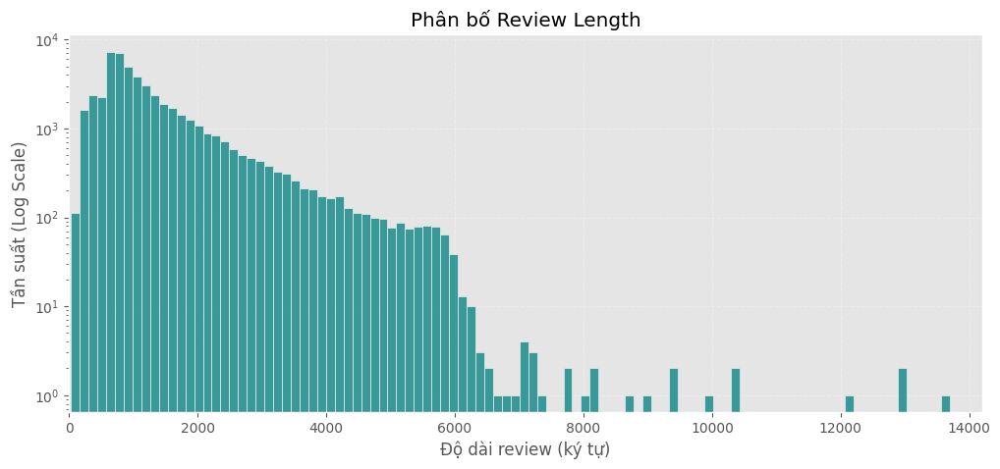


=== NHẬN XÉT ===
- Độ dài trung bình của review khoảng 1309 ký tự.
- Độ dài điển hình (median) là 970 ký tự.
- Review ngắn nhất có 32 ký tự, dài nhất đạt 13704 ký tự.
- Phân bố có xu hướng lệch phải, một số review rất dài so với phần còn lại.
Positive Lexicon size: 71172
Negative Lexicon size: 64853
Neutral Words size: 38375


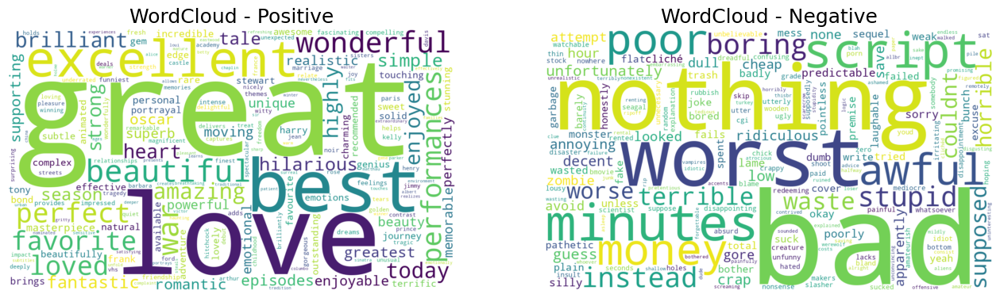

In [6]:
 # Thống kê mô tả
# --- ĐỘ DÀI REVIEW (Ký tự) ---
df["review_length"] = df["review"].astype(str).apply(len)

# --- SỐ LƯỢNG TỪ ---
df["word_count"] = df["review"].astype(str).apply(lambda x: len(x.split()))

# --- ĐỘ DÀI CÂU TRUNG BÌNH ---
def get_avg_sentence_length(text):
    sentences = re.split(r"[.!?]+[\s]*", str(text))
    sentences = [s.strip() for s in sentences if s.strip() != ""]

    if not sentences:
        return 0.0

    lengths = [len(s.split()) for s in sentences]
    return np.mean(lengths)

df["avg_sentence_length"] = df["review"].apply(get_avg_sentence_length)

# --- BẢNG THỐNG KÊ MÔ TẢ ---
cols = ["review_length", "word_count", "avg_sentence_length"]
desc_stats = df[cols].describe().loc[["count", "mean", "min", "max"]]

print("=== BẢNG THỐNG KÊ MÔ TẢ ===")
print(desc_stats)

# --- NHẬN XÉT VỀ REVIEW LENGTH ---
min_val = df["review_length"].min()
max_val = df["review_length"].max()

plt.figure(figsize=(12, 5))
sns.histplot(df["review_length"], bins=100, kde=False, color="teal")
plt.xlim(0, max_val + 500)
plt.yscale("log")

plt.title("Phân bố Review Length")
plt.xlabel("Độ dài review (ký tự)")
plt.ylabel("Tần suất (Log Scale)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

mean_len = df["review_length"].mean()
median_len = df["review_length"].median()
min_len = df["review_length"].min()
max_len = df["review_length"].max()

print("\n=== NHẬN XÉT ===")
print(f"- Độ dài trung bình của review khoảng {int(mean_len)} ký tự.")
print(f"- Độ dài điển hình (median) là {int(median_len)} ký tự.")
print(f"- Review ngắn nhất có {int(min_len)} ký tự, dài nhất đạt {int(max_len)} ký tự.")
print("- Phân bố có xu hướng lệch phải, một số review rất dài so với phần còn lại.")

# --- WORDCLOUD: TỰ HỌC LEXICON CẢM XÚC TỪ IMDB + BOOST ĐÚNG CHIỀU ---
stop_words = set(stopwords.words("english"))

def tokenize(text):
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = [w for w in text.split() if w.isalpha() and w not in stop_words and len(w) >= 3]
    return tokens

pos_tokens = []
neg_tokens = []

for text in df[df["sentiment"] == "positive"]["review"]:
    pos_tokens.extend(tokenize(text))

for text in df[df["sentiment"] == "negative"]["review"]:
    neg_tokens.extend(tokenize(text))

pos_freq = Counter(pos_tokens)
neg_freq = Counter(neg_tokens)

positive_lexicon = set()
negative_lexicon = set()
neutral_words = set()

ratio = 2.0
all_words = set(pos_freq.keys()).union(set(neg_freq.keys()))

for word in all_words:
    fp = pos_freq[word]
    fn = neg_freq[word]

    if fp > fn * ratio:
        positive_lexicon.add(word)
    elif fn > fp * ratio:
        negative_lexicon.add(word)
    else:
        neutral_words.add(word)

print("Positive Lexicon size:", len(positive_lexicon))
print("Negative Lexicon size:", len(negative_lexicon))
print("Neutral Words size:", len(neutral_words))
def build_positive_text(text, boost_factor=5):
    words = tokenize(text)
    processed = []
    for w in words:
        if w in neutral_words or w in negative_lexicon:
            continue
        if w in positive_lexicon:
            processed.extend([w] * boost_factor)
        else:
            processed.append(w)
    return " ".join(processed)

def build_negative_text(text, boost_factor=5):
    words = tokenize(text)
    processed = []
    for w in words:
        if w in neutral_words or w in positive_lexicon:
            continue
        if w in negative_lexicon:
            processed.extend([w] * boost_factor)
        else:
            processed.append(w)
    return " ".join(processed)

positive_text_raw = " ".join(df[df["sentiment"] == "positive"]["review"].astype(str))
negative_text_raw = " ".join(df[df["sentiment"] == "negative"]["review"].astype(str))

positive_cleaned = build_positive_text(positive_text_raw)
negative_cleaned = build_negative_text(negative_text_raw)

wc_positive = WordCloud(
    width=1200, height=700, background_color="white",
    stopwords=stop_words, max_words=200, collocations=False
).generate(positive_cleaned)

wc_negative = WordCloud(
    width=1200, height=700, background_color="white",
    stopwords=stop_words, max_words=200, collocations=False
).generate(negative_cleaned)

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(wc_positive, interpolation="bilinear")
plt.title("WordCloud - Positive", fontsize=18)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(wc_negative, interpolation="bilinear")
plt.title("WordCloud - Negative", fontsize=18)
plt.axis("off")

plt.show()

In [7]:
 # TẠO BÁO CÁO EDA
# ============================
print("\n==============================")
print("📘 BÁO CÁO EDA – IMDB MOVIE REVIEWS")
print("==============================\n")

# ============================================================
# 1) GIỚI THIỆU DATASET
# ============================================================
print("1) GIỚI THIỆU DATASET")
print("-----------------------")

total_rows = len(df)
unique_sentiments = df["sentiment"].unique()
pos_count = (df["sentiment"] == "positive").sum()
neg_count = (df["sentiment"] == "negative").sum()

print(f"- Tổng số dòng dữ liệu: {total_rows}")
print(f"- Nhãn sentiment gồm: {unique_sentiments}")
print(f"   • Positive: {pos_count}")
print(f"   • Negative: {neg_count}\n")

# ============================================================
# 2) MÔ TẢ DỮ LIỆU + THỐNG KÊ
# ============================================================
print("2) MÔ TẢ DỮ LIỆU + THỐNG KÊ")
print("---------------------------")

print("\n📌 Missing values:")
print(df[["review", "sentiment"]].isnull().sum())

print("\n📌 Outliners:")
print(f"=> Có {len(sentiment_outliers)} giá trị ngoại lai trong cột sentiment.\n")

duplicate_rows = df.duplicated().sum()
print(f"\n📌 Số dòng trùng lặp: {duplicate_rows}")

print("\n📌 Thống kê độ dài review:")
print(df[["review_length", "word_count", "avg_sentence_length"]].describe())

print("\n➡ Nhận xét nhanh:")
print("- Review dài/ngắn không đồng đều → cần chuẩn hoá độ dài khi train.")
print("- Phân bố độ dài lệch phải → nhiều review rất dài.\n")

# ============================================================
# 3) BIỂU ĐỒ + PHÂN TÍCH XU HƯỚNG
# ============================================================
print("3) BIỂU ĐỒ + PHÂN TÍCH XU HƯỚNG")
print("---------------------------------")

print("\n Thông qua Wordcloud rút ra được các từ khóa nổi bật bao gồm :")
print("- Positive nổi bật: love, great, amazing, beautiful, excellent, fun...")
print("- Negative nổi bật: bad, awful, boring, worst, waste, stupid, terrible...")

print("\n Ý nghĩa:")
print("- Các từ khóa positive và negative được phân biệt một cách rõ ràng.")
print("- Các từ neutral (movie, film, time) sẽ không xuất hiện.")

# ============================================================
# 4) KẾT LUẬN
# ============================================================
print("\n4) KẾT LUẬN")
print("------------")

print("\n*** Kết quả thu thập được từ việc phân tích bộ dataset:")
print("- Không có missing values.")
print("- Không có outliers trong sentiment.")
print("- Độ dài review biến thiên lớn → cần chuẩn hoá.")

print("- Từ vựng cảm xúc có sự phân biệt rõ rệt giữa positive và negative.")

print("\n*** Vấn đề tồn tại:")
print("- Text không đồng đều độ dài → cần truncate hoặc pad để có thể cho mô hình SVM học.")
print("- Một số review quá dài gây nhiễu.")
print("- Cần bổ sung bước NLP cleaning trước khi huấn luyện mô hình.")

print("\n*** Hướng xử lý tiếp theo:")
print("- Làm sạch văn bản: lowercase, loại bỏ HTML tags (br), loại bỏ dấu câu để giảm thiểu nhiễu.")
print("- Đưa từ trở về lại dạng động từ gốc Verb.")
print("- Vector hoá bằng TF-IDF hoặc embeddings.")
print("- Huấn luyện mô hình phân loại bằng SVM.")

print("\n=> TÓM TẮT NGẮN GỌN:")
print(
    "“Dataset review phim IMDB có phân bố từ ngữ rõ ràng theo cảm xúc, "
    "độ dài review lệch phải, và cần chuẩn hoá + NLP cleaning trước khi bắt đầu thực hiện train mô hình.”"
)


📘 BÁO CÁO EDA – IMDB MOVIE REVIEWS

1) GIỚI THIỆU DATASET
-----------------------
- Tổng số dòng dữ liệu: 50000
- Nhãn sentiment gồm: ['positive' 'negative']
   • Positive: 25000
   • Negative: 25000

2) MÔ TẢ DỮ LIỆU + THỐNG KÊ
---------------------------

📌 Missing values:
review       0
sentiment    0
dtype: int64

📌 Outliners:
=> Có 0 giá trị ngoại lai trong cột sentiment.


📌 Số dòng trùng lặp: 418

📌 Thống kê độ dài review:
       review_length    word_count  avg_sentence_length
count   50000.000000  50000.000000         50000.000000
mean     1309.431020    231.156940            18.403723
std       989.728014    171.343997             8.989188
min        32.000000      4.000000             2.000000
25%       699.000000    126.000000            13.750000
50%       970.000000    173.000000            17.125000
75%      1590.250000    280.000000            21.244318
max     13704.000000   2470.000000           374.000000

➡ Nhận xét nhanh:
- Review dài/ngắn không đồng đều → cần chu

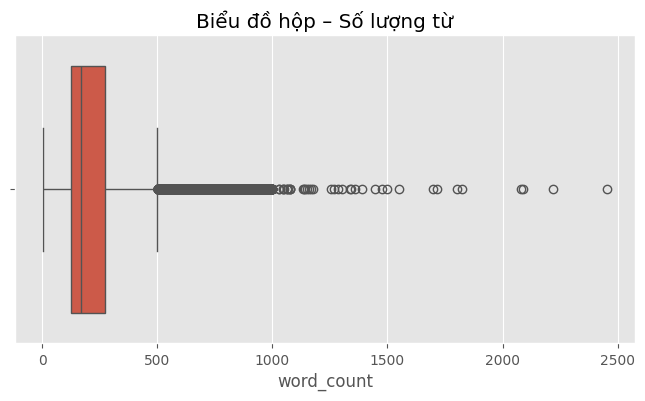

Đã loại bỏ các đánh giá có < 5 từ: 1
Số dòng sau khi lọc: 49999
Text preprocessing & TF-IDF completed
Samples: 49999
Features: 5000


In [8]:
# ===================== CLEAN TEXT + TF-IDF + BOXPLOT =====================

import pandas as pd
import re
import string
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Tham số ----
MIN_WORDS = 5
MAX_LEN = 100
MAX_FEATURES = 5000

# ---- Làm sạch văn bản ----
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review_clean"] = df["review"].apply(clean_text)

# ---- Tính số từ ----
df["word_count"] = df["review_clean"].str.split().str.len()

# ---- Boxplot Word Count ----
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["word_count"])
plt.title("Biểu đồ hộp – Số lượng từ")
plt.show()

# ---- Lọc review quá ngắn ----
rows_before = len(df)
df = df[df["word_count"] >= MIN_WORDS]
rows_after = len(df)

print(f"Đã loại bỏ các đánh giá có < {MIN_WORDS} từ:", rows_before - rows_after)
print("Số dòng sau khi lọc:", rows_after)

# ---- Truncate (KHÔNG padding) ----
def truncate_text(text, max_len=MAX_LEN):
    words = text.split()
    if len(words) > max_len:
        words = words[:max_len]
    return " ".join(words)

df["review_processed"] = df["review_clean"].apply(truncate_text)

# ---- Vector hoá TF-IDF ----
vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(df["review_processed"])

print("Text preprocessing & TF-IDF completed")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])


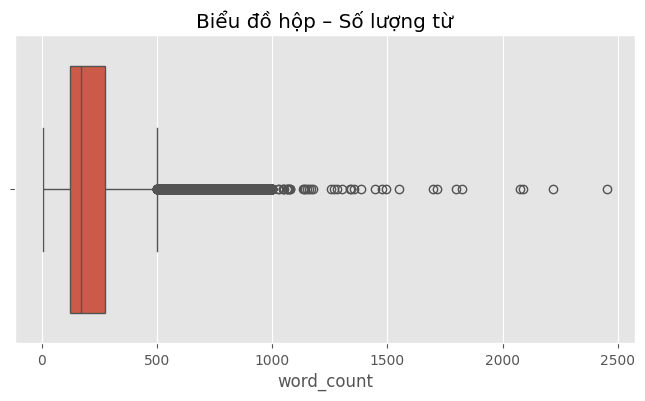

Đã loại bỏ các đánh giá có < 5 từ: 0
Số dòng sau khi lọc: 49999
Text preprocessing & TF-IDF completed
Samples: 49999
Features: 5000
Đã lưu file preprocessor.pkl


In [9]:
# ===================== CLEAN TEXT + TF-IDF + BOXPLOT =====================

import pandas as pd
import re
import string
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# ---- Tham số ----
MIN_WORDS = 5
MAX_LEN = 100
MAX_FEATURES = 5000

# ---- Làm sạch văn bản ----
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review_clean"] = df["review"].apply(clean_text)

# ---- Tính số từ ----
df["word_count"] = df["review_clean"].str.split().str.len()

# ---- Boxplot Word Count ----
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["word_count"])
plt.title("Biểu đồ hộp – Số lượng từ")
plt.show()

# ---- Lọc review quá ngắn ----
rows_before = len(df)
df = df[df["word_count"] >= MIN_WORDS]
rows_after = len(df)

print(f"Đã loại bỏ các đánh giá có < {MIN_WORDS} từ:", rows_before - rows_after)
print("Số dòng sau khi lọc:", rows_after)

# ---- Truncate (KHÔNG padding) ----
def truncate_text(text, max_len=MAX_LEN):
    words = text.split()
    if len(words) > max_len:
        words = words[:max_len]
    return " ".join(words)

df["review_processed"] = df["review_clean"].apply(truncate_text)

# ---- Vector hoá TF-IDF ----
vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    ngram_range=(1, 2),
    max_df=0.9,
    min_df=5
)

X = vectorizer.fit_transform(df["review_processed"])

print("Text preprocessing & TF-IDF completed")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])

# ---- SAVE preprocessor ----
joblib.dump(vectorizer, "preprocessor.pkl")
print("Đã lưu file preprocessor.pkl")

In [10]:
# --- CHUẨN BỊ DỮ LIỆU ĐẦU VÀO ---

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

print("1. Đang mã hóa nhãn...")
# Chuyển đổi: positive -> 1, negative -> 0
# (Giả sử cột chứa nhãn cảm xúc của bạn tên là 'sentiment')
df['label'] = df['sentiment'].apply(lambda x: 1 if x == 'positive' else 0)

print("2. Đang chia tập Train/Test...")
# Chia dữ liệu theo tỷ lệ 80% Train - 20% Test
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['review'],       # Cột chứa văn bản
    df['label'],        # Cột chứa nhãn (0/1)
    test_size=0.2,      # 20% dữ liệu để test
    random_state=42,    # Giữ cố định kết quả chia
    stratify=df['label'] # Đảm bảo tỷ lệ 0/1 đều nhau ở cả 2 tập
)

print("3. Đang tạo ma trận TF-IDF...")
# Khởi tạo bộ vector hóa TF-IDF
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')

# Học từ tập Train và chuyển đổi
X_train_tfidf = tfidf.fit_transform(X_train_text)

# Chuyển đổi tập Test
X_test_tfidf = tfidf.transform(X_test_text)

# --- KIỂM TRA KẾT QUẢ---
print("\n--- HOÀN THÀNH BƯỚC CHUẨN BỊ ---")
print(f"Kích thước tập Train gốc: {len(X_train_text)}")
print(f"Kích thước tập Test gốc:  {len(X_test_text)}")
print(f"Kích thước ma trận TF-IDF Train (Input cho model): {X_train_tfidf.shape}")
print(f"Kích thước ma trận TF-IDF Test (Input để dự báo):  {X_test_tfidf.shape}")

1. Đang mã hóa nhãn...
2. Đang chia tập Train/Test...
3. Đang tạo ma trận TF-IDF...

--- HOÀN THÀNH BƯỚC CHUẨN BỊ ---
Kích thước tập Train gốc: 39999
Kích thước tập Test gốc:  10000
Kích thước ma trận TF-IDF Train (Input cho model): (39999, 5000)
Kích thước ma trận TF-IDF Test (Input để dự báo):  (10000, 5000)


In [11]:
# --- HUẤN LUYỆN MÔ HÌNH ---

from sklearn.svm import LinearSVC

print("4. Đang khởi tạo mô hình LinearSVC...")
# Theo yêu cầu PDF: Sử dụng LinearSVC với tham số mặc định làm Baseline
model = LinearSVC(random_state=42)

print("5. Đang huấn luyện (Fitting)...")
# Đưa dữ liệu Train vào để mô hình học
model.fit(X_train_tfidf, y_train)

print("6. Đang dự báo (Predicting)...")
# Dùng mô hình đã học để dự đoán nhãn cho tập Test
y_pred = model.predict(X_test_tfidf)

print("\n--- HUẤN LUYỆN HOÀN TẤT ---")
print("Mô hình đã học xong và đã có kết quả dự báo trong biến 'y_pred'.")

4. Đang khởi tạo mô hình LinearSVC...
5. Đang huấn luyện (Fitting)...
6. Đang dự báo (Predicting)...

--- HUẤN LUYỆN HOÀN TẤT ---
Mô hình đã học xong và đã có kết quả dự báo trong biến 'y_pred'.


7. Đang tính toán các chỉ số đánh giá...

=== KẾT QUẢ ĐÁNH GIÁ (Trên tập Test) ===
Accuracy (Độ chính xác):  0.8799  (Mục tiêu ~0.85)
Precision (Độ chuẩn xác): 0.8753
Recall (Độ nhạy):         0.8860
F1-score:                 0.8806

--- Báo cáo chi tiết (Classification Report) ---
              precision    recall  f1-score   support

    Negative       0.88      0.87      0.88      5000
    Positive       0.88      0.89      0.88      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000


8. Đang vẽ Confusion Matrix...


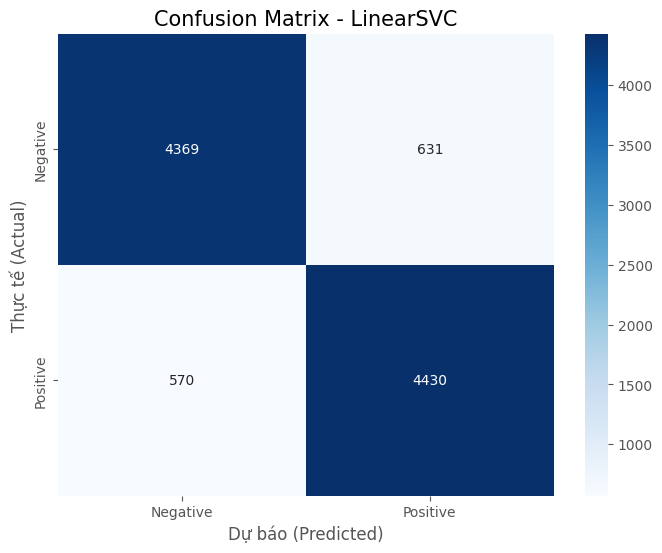

In [12]:
# --- ĐÁNH GIÁ MÔ HÌNH & VẼ CONFUSION MATRIX ---
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("7. Đang tính toán các chỉ số đánh giá...")

# Tính các chỉ số
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# In kết quả ra màn hình
print(f"\n=== KẾT QUẢ ĐÁNH GIÁ (Trên tập Test) ===")
print(f"Accuracy (Độ chính xác):  {acc:.4f}  (Mục tiêu ~0.85)")
print(f"Precision (Độ chuẩn xác): {prec:.4f}")
print(f"Recall (Độ nhạy):         {rec:.4f}")
print(f"F1-score:                 {f1:.4f}")

# In báo cáo chi tiết
print("\n--- Báo cáo chi tiết (Classification Report) ---")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

# Vẽ Confusion Matrix dạng Heatmap
print("\n8. Đang vẽ Confusion Matrix...")
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True,         # Hiển thị con số cụ thể trong ô
            fmt='d',            # Định dạng số nguyên
            cmap='Blues',       # Tông màu xanh
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])

plt.title('Confusion Matrix - LinearSVC', fontsize=15)
plt.xlabel('Dự báo (Predicted)', fontsize=12)
plt.ylabel('Thực tế (Actual)', fontsize=12)
plt.show()

9. Đang tính toán và vẽ ROC Curve...
AUC Score: 0.9517


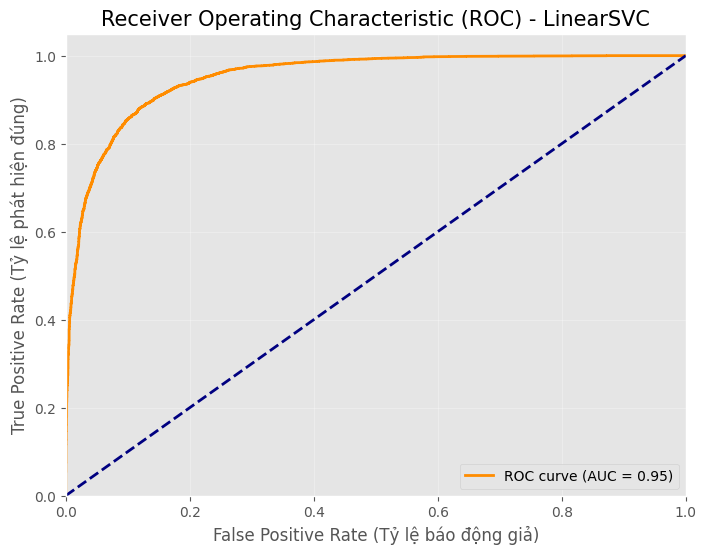

In [13]:
# ---ROC CURVE & TÍNH AUC ---
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

print("9. Đang tính toán và vẽ ROC Curve...")

# 1. Lấy điểm quyết định (Decision Function) từ mô hình
# (LinearSVC dùng decision_function để lấy điểm số thay vì predict_proba)
y_score = model.decision_function(X_test_tfidf)

# 2. Tính toán FPR (False Positive Rate) và TPR (True Positive Rate)
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# 3. Tính diện tích dưới đường cong (AUC Score)
roc_auc = auc(fpr, tpr)
print(f"AUC Score: {roc_auc:.4f}")

# 4. Vẽ biểu đồ
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Đường chéo ngẫu nhiên (50%)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Tỷ lệ báo động giả)', fontsize=12)
plt.ylabel('True Positive Rate (Tỷ lệ phát hiện đúng)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) - LinearSVC', fontsize=15)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, RocCurveDisplay
from google.colab import drive
from sklearn.calibration import CalibratedClassifierCV

# 1. Kết nối Google Drive
drive.mount('/content/drive')

# 2. Tạo cấu trúc thư mục nếu chưa có
path_project = '/content/drive/MyDrive/Project_ML'
path_models = os.path.join(path_project, 'models')
path_data = os.path.join(path_project, 'data')

os.makedirs(path_models, exist_ok=True)
os.makedirs(path_data, exist_ok=True)

# --- BƯỚC HUẤN LUYỆN MÔ HÌNH (DÀNH CHO SV3) ---

print("4. Đang huấn luyện mô hình Baseline (LinearSVC)...")
# Khởi tạo mô hình với tham số mặc định theo yêu cầu
linear_svc = LinearSVC(random_state=42)
baseline_model = CalibratedClassifierCV(linear_svc, method='sigmoid')
baseline_model.fit(X_train_tfidf, y_train)

# --- BƯỚC LƯU FILE ---

print("5. Đang lưu các file cần thiết vào Drive...")

# Lưu mô hình Baseline
joblib.dump(baseline_model, os.path.join(path_models, 'baseline_svm.pkl'))

# Lưu bộ TF-IDF Vectorizer
joblib.dump(tfidf, os.path.join(path_models, 'tfidf_vectorizer.pkl'))

# Lưu ma trận TF-IDF của tập test
joblib.dump(X_test_tfidf, os.path.join(path_data, 'X_test_tfidf.pkl'))

# Lưu dữ liệu test để SV4 thực hiện phân tích lỗi (Error Analysis)
test_data = {
    'X_test_text': X_test_text, # Văn bản gốc để đọc lỗi
    'X_test_tfidf': X_test_tfidf, # Ma trận số để chạy model
    'y_test': y_test,             # Nhãn thật để đối chiếu
    'y_pred': y_pred              # Dự đoán của SV3 để SV4 so sánh
}
joblib.dump(test_data, os.path.join(path_project, 'data/test_results.pkl'))

print("\n✅ TẤT CẢ ĐÃ ĐƯỢC LƯU THÀNH CÔNG!")
print(f"Thư mục mô hình: {path_models}")
print(f"Thư mục dữ liệu: {path_data}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
4. Đang huấn luyện mô hình Baseline (LinearSVC)...
5. Đang lưu các file cần thiết vào Drive...

✅ TẤT CẢ ĐÃ ĐƯỢC LƯU THÀNH CÔNG!
Thư mục mô hình: /content/drive/MyDrive/Project_ML/models
Thư mục dữ liệu: /content/drive/MyDrive/Project_ML/data
